<a href="https://colab.research.google.com/github/theeduazizjon-cell/computer_vision/blob/master/pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

"Pytorch" installation with pip

In [25]:
pip install torch

In [26]:
#Import Pytorch and matplotlin
import torch
from torch import nn #nn contains all fo Pytorh's building blocks for nearal networks
import matplotlib.pyplot as plt


checking the version

In [27]:
print(torch.__version__)

2.11.0+cu130


checking avaailability of cuda

In [28]:
print("CUDA available:", torch.cuda.is_available())

#SetUp device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"using device: {device}")

CUDA available: True
using device: cuda


In [29]:
scalar = torch.tensor(5) #0d
print("scalar:", scalar)
print("Shape:", scalar.shape)
print("Number of dimensions:", scalar.ndim)
print("Size:", scalar.size())

scalar: tensor(5)
Shape: torch.Size([])
Number of dimensions: 0
Size: torch.Size([])


In [30]:
vector = torch.tensor([1,2, 3])
print("vector:", vector)
print("Shape:", vector.shape)
print("Number of dimensions:", vector.ndim)
print("Size:", vector.size())

vector: tensor([1, 2, 3])
Shape: torch.Size([3])
Number of dimensions: 1
Size: torch.Size([3])


In [31]:
matrix = torch.tensor([[1, 2, 3], [4, 5, 6]]) #2d

print("Matrix:", matrix)
print("Shape:", matrix.shape)
print("Number of dimensions:", matrix.ndim)

Matrix: tensor([[1, 2, 3],
        [4, 5, 6]])
Shape: torch.Size([2, 3])
Number of dimensions: 2


In [32]:
tensor3d = torch.stack([matrix, matrix + 10]) #3d

print("tesnor3d:", tensor3d)
print("Shape:", tensor3d.shape)
print("Number of dimensions:", tensor3d.ndim)

tesnor3d: tensor([[[ 1,  2,  3],
         [ 4,  5,  6]],

        [[11, 12, 13],
         [14, 15, 16]]])
Shape: torch.Size([2, 2, 3])
Number of dimensions: 3


In [33]:
random_numbers = torch.rand(2,3)
print("Random numbers:", random_numbers)
print("Data typr:", random_numbers.dtype)
print("Device of random numbers", random_numbers.device)

Random numbers: tensor([[0.3829, 0.9593, 0.3904],
        [0.6009, 0.2566, 0.7936]])
Data typr: torch.float32
Device of random numbers cpu


In [34]:
print("Zeros:", torch.zeros(3,3))

Zeros: tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


In [35]:
print("Ones:", torch.ones(2,4))

Ones: tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]])


Mathematical operations on tensors

In [36]:
x = torch.tensor([[1,2], [3, 4]])

y = torch.tensor([[5,6], [7,8]])

#Element-wise addition
print("Addition:",x + y)

#Element-wise multiplication
print("Multiplication:", x*y)

#Matrix multiplication
print("Matrix multiplication:", x@ y )

#x
[[1,2],
 [3,4]]

#y
[[5,6],
 [7,8]]



Addition: tensor([[ 6,  8],
        [10, 12]])
Multiplication: tensor([[ 5, 12],
        [21, 32]])
Matrix multiplication: tensor([[19, 22],
        [43, 50]])


[[5, 6], [7, 8]]

#[1,2] * [5,7]= 1 * 5 + 2 * 7 = 5 + 12 = 19

#[1,2] * [6,8] = 1 * 6 + 2 * 8 = 6 + 16 = 22

In [37]:
#Import Pytorch and matplotlib
import torch
from torch import nn #nn contains all fo Pytorch's building blocks for neural networks
import matplotlib.pyplot as plt

#Check Pytorch version
torch.__version__


'2.11.0+cu130'

In [38]:
#Setup device agnostic code

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [39]:
#Create weight and bias
weight = 0.7
bias = 0.3

#Create range values
start = 0
end = 1
step = 0.02

#Create X and Y(features and labels)
x = torch.arange(start, end, step).unsqueeze(dim=1) #without usnqueeze, errors will happen later on(shapes within linear layers)
y = weight * x + bias

#Split data
train_split = int(0.8 *len(x))
x_train, y_train =x[:train_split], y[:train_split]
x_test , y_test = x[train_split:], y[train_split:]

len(x_train), len(y_train), len(x_test), len(y_test)

(40, 40, 10, 10)

In [40]:
def plot_predictions(train_data = x_train,
                     train_labels = y_train,
                     test_data = x_test,
                     test_labels = y_test,
                     predictions = None):

  plt.figure(figsize=(10,7))

  #Plot training data in blue
  plt.scatter(train_data, train_labels, c='b', s=4, label='Training data')

  #Plot test data in green
  plt.scatter(test_data, test_labels, c='g', s=4, label='Testing data')

  if predictions is not None:
    plt.scatter(test_data, predictions, c='r', s=4, label = 'Predictions')

  plt.legend(prop={'size':14})

In [41]:
#Sublcass nn.Module to make our model
class LinearRegressionModelV2(nn.Module):
  def __init__(self):
    super().__init__()
  #Use nn.Linear() for creating the model parameters
    self.linear_layer =nn.Linear(in_features=1,
                               out_features=1)

  #Define the forward computation (input data x flows through nn.Linear())
  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.linear_layer(x)

  #Set the manual seed when creating the model (this isn't always needed but used for demonstrative purposes, try commenting it out and seeing what happens)
torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
model_1 ,  model_1.state_dict(),

(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [42]:
#Create loss function
loss_fn = nn.L1Loss()

#Create optimizer
optimizer = torch.optim.SGD(params=model_1.parameters(), #optimize newly model's parameters
                            lr=0.01)



Text(0.5, 1.0, 'Predictions before training (red = random guesses)')

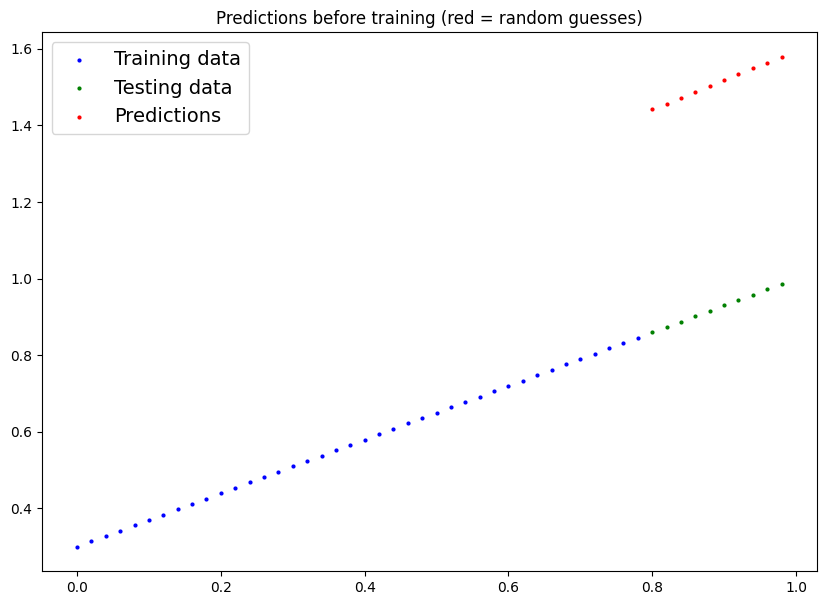

In [43]:
#See model's untrained predictions (on test set)
model_1.eval()
with torch.inference_mode():
  y_preds_early = model_1(x_test)

plot_predictions(predictions = y_preds_early)
plt.title("Predictions before training (red = random guesses)")

In [45]:
from IPython.utils.terminal import toggle_set_term_title
#Set the number of epochs
epochs = 1000

#Put model on the available device
model_1 = model_1.to(device)

#Put data on the available device
#Without this.error will happen (not all model/data on device)
x_train = x_train.to(device)
x_test = x_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

for epoch in range(epochs):
  ###Training
  model_1.train() #train mode is on by default after constructions

  # 1. Forward pass
  y_pred = model_1(x_train)

  # 2.Calculate loss
  loss = loss_fn(y_pred, y_train)

  # 3.Zero and optimizer
  optimizer.zero_grad()

  # 4.Loss backward
  loss.backward()

  # 5. Step the optimizer
  optimizer.step()

  ### Testing
  model_1.eval() #put the modelk in evaluation mode for testing (inference)
  # 1. Forward pass
  with torch.inference_mode():
    test_pred = model_1(x_test)

    # 2.Calculate the loss
    test_loss = loss_fn(test_pred, y_test)

  if epoch % 100 == 0:
    print(f"Epoch: {epoch} | Train loss:{loss} | Test loss:{test_loss}")

Epoch: 0 | Train loss:0.6950885057449341 | Test loss:0.5723475813865662
Epoch: 100 | Train loss:0.06697963923215866 | Test loss:0.17378948628902435
Epoch: 200 | Train loss:0.05234399437904358 | Test loss:0.14334146678447723
Epoch: 300 | Train loss:0.03771180659532547 | Test loss:0.11212928593158722
Epoch: 400 | Train loss:0.02308008074760437 | Test loss:0.08168168365955353
Epoch: 500 | Train loss:0.008443928323686123 | Test loss:0.0504700243473053
Epoch: 600 | Train loss:0.006397950928658247 | Test loss:0.04563617706298828
Epoch: 700 | Train loss:0.006397950928658247 | Test loss:0.04563617706298828
Epoch: 800 | Train loss:0.006397950928658247 | Test loss:0.04563617706298828
Epoch: 900 | Train loss:0.006397950928658247 | Test loss:0.04563617706298828


In [46]:
# Turn model into evaluation mode
model_1.eval()

#Make predictions on the test data
with torch.inference_mode():
  y_preds = model_1(x_test)
y_preds

tensor([[0.8036],
        [0.8233],
        [0.8431],
        [0.8628],
        [0.8826],
        [0.9023],
        [0.9221],
        [0.9418],
        [0.9616],
        [0.9813]], device='cuda:0')

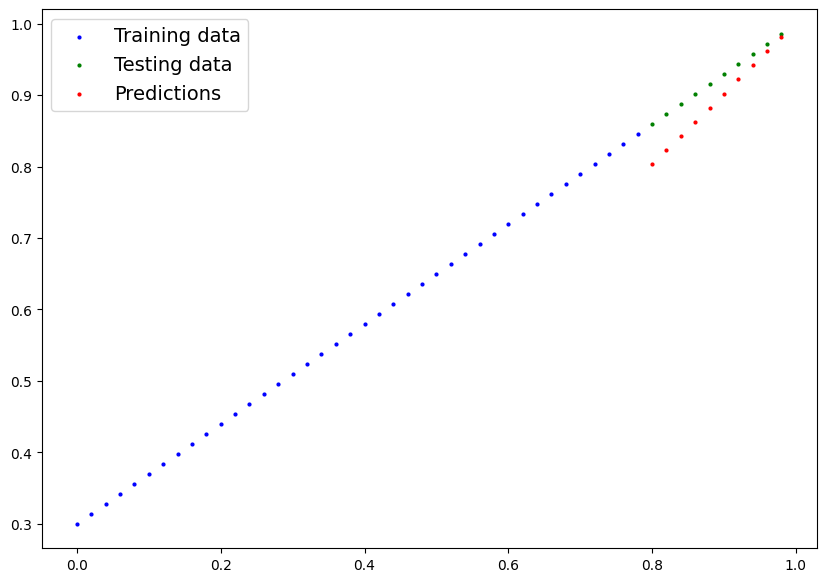

In [48]:
#Put data on the CPU and plot it
plot_predictions(predictions=y_preds.cpu())